#Data Sourcing

we started our process by sourcing our CSV file data on Sleep Health and Lifestyle from Kaggle. Kaggle is a popular and trusted platform for data science and machine learning practitioners. It offers a wide array of datasets that are freely available for analysis.

The Link to the Kaggle dataset is as follow: https://www.kaggle.com/datasets/uom190346a/sleep-health-and-lifestyle-dataset

IMPORTING THE NECESSARY LIBRARIES

A library is a collection of hierarchically structured directories of Python code consisting of sub-packages and modules.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.multioutput import MultiOutputClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

DATA OVERVIEW

In [ ]:

df = pd.read_csv('/content/Sleep_Stress data.csv')

A check to see all the cells that are empty among all the columns.

In [ ]:
df.isnull().sum()

Unnamed: 0                   0
Person ID                    0
Gender                       0
Age                          0
Occupation                   0
Sleep Duration               0
Quality of Sleep             0
Physical Activity Level      0
Stress Level                 0
BMI Category                 0
Blood Pressure               0
Heart Rate                   0
Daily Steps                  0
Sleep Disorder             816
dtype: int64

In [ ]:

df['Sleep Disorder'].fillna('No Disorder', inplace=True)


In [ ]:
df.head()

,Unnamed: 0,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,0,1,Male,0,Software Engineer,6.1,2,4,3,Overweight,126/83,10,6,No Disorder
1,1,2,Male,1,Doctor,6.2,2,9,5,Normal,125/80,8,19,No Disorder
2,2,3,Male,1,Doctor,6.2,2,9,5,Normal,125/80,8,19,No Disorder
3,3,4,Male,1,Sales Representative,5.9,0,0,5,Obese,140/90,17,0,Sleep Apnea
4,4,5,Male,1,Sales Representative,5.9,0,0,5,Obese,140/90,17,0,Sleep Apnea


In [ ]:
df['BMI Category'].value_counts()

BMI Category
Normal           736
Overweight       538
Normal Weight     67
Obese             33
Name: count, dtype: int64

In [ ]:
df['Stress Level'].value_counts()

Stress Level
0    280
5    252
2    244
1    242
4    182
3    174
Name: count, dtype: int64

In [ ]:
df['Sleep Disorder'].value_counts()

Sleep Disorder
No Disorder    816
Sleep Apnea    287
Insomnia       271
Name: count, dtype: int64

In [ ]:
df['Occupation'].value_counts()

Occupation
Doctor                  265
Nurse                   260
Engineer                250
Lawyer                  166
Teacher                 146
Accountant              122
Salesperson             118
Scientist                20
Software Engineer        16
Sales Representative      7
Manager                   4
Name: count, dtype: int64

DATA PREPROCESSING

This is where the categorical data (the ones that are in texts) was converted into numerical data (numbers) so that the model can work with them. We prioritized mapping over One-hot Encoding because of simplicity in converting the categorical data, and to preserve the ordering in the ordinal data like 'BMI Category' and 'Sleep Disorder'. Mapping is a process that allows the transformation of multiple columns at once.

In [ ]:
df['Gender'] = df['Gender'].map({'Female': 0, 'Male': 1})
df['Occupation'] = df['Occupation'].map({'Accountant': 1, 'Doctor': 2, 'Engineer': 3, 'Lawyer': 4, 'Manager': 5, 'Nurse':6,  'Salesperson': 7, 'Sales Representative': 8,
                                         'Scientist': 9,'Software Engineer':10, 'Teacher': 11})
df['BMI Category'] = df['BMI Category'].map({'Underweight': 0, 'Normal Weight': 1, 'Normal': 1,  'Overweight': 2, 'Obese': 3})
df['Sleep Disorder'] = df['Sleep Disorder'].map({'No Disorder': 0, 'Insomnia': 1, 'Sleep Apnea': 2})

In [ ]:
df.head()

,Unnamed: 0,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,0,1,1,0,10,6.1,2,4,3,2,126/83,10,6,0
1,1,2,1,1,2,6.2,2,9,5,1,125/80,8,19,0
2,2,3,1,1,2,6.2,2,9,5,1,125/80,8,19,0
3,3,4,1,1,8,5.9,0,0,5,3,140/90,17,0,2
4,4,5,1,1,8,5.9,0,0,5,3,140/90,17,0,2


Part of the pre-processing is splitting the 'Blood Pressure' column into 'SystolicBP' and 'DiastolicBP', so that each

In [ ]:
#splitting the blodd pressure to create new columns
df[['SystolicBP', 'DiastolicBP']] = df['Blood Pressure'].apply(lambda x: pd.Series(str(x).split('/')))
df.drop(columns=['Blood Pressure'], inplace=True)
df.head()


,Unnamed: 0,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Heart Rate,Daily Steps,Sleep Disorder,SystolicBP,DiastolicBP
0,0,1,1,0,10,6.1,2,4,3,2,10,6,0,126,83
1,1,2,1,1,2,6.2,2,9,5,1,8,19,0,125,80
2,2,3,1,1,2,6.2,2,9,5,1,8,19,0,125,80
3,3,4,1,1,8,5.9,0,0,5,3,17,0,2,140,90
4,4,5,1,1,8,5.9,0,0,5,3,17,0,2,140,90


In [ ]:
df.dtypes

Unnamed: 0                   int64
Person ID                    int64
Gender                       int64
Age                          int64
Occupation                   int64
Sleep Duration             float64
Quality of Sleep             int64
Physical Activity Level      int64
Stress Level                 int64
BMI Category                 int64
Heart Rate                   int64
Daily Steps                  int64
Sleep Disorder               int64
SystolicBP                   int64
DiastolicBP                  int64
dtype: object

In [ ]:
df.SystolicBP = df.SystolicBP.astype('int')

df.DiastolicBP = df.DiastolicBP.astype('int')

In [ ]:
df.columns

Index(['Unnamed: 0', 'Person ID', 'Gender', 'Age', 'Occupation',
       'Sleep Duration', 'Quality of Sleep', 'Physical Activity Level',
       'Stress Level', 'BMI Category', 'Heart Rate', 'Daily Steps',
       'Sleep Disorder', 'SystolicBP', 'DiastolicBP'],
      dtype='object')

SPLITTING THE DATASET INTO TRAIN, VALIDATION AND TEST DATASET

In [ ]:

X = df.drop(columns=['Unnamed: 0','Person ID', 'Stress Level', 'Sleep Disorder'])

y = df[['Stress Level', 'Sleep Disorder']]

# Split the data into train and test sets
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42)

# Split the remaining data into validation and test sets
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

# Print the shapes of the resulting data sets
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_val shape:", X_val.shape)
print("y_val shape:", y_val.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)



# Standardize the feature data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)


X_train shape: (961, 11)
y_train shape: (961, 2)
X_val shape: (206, 11)
y_val shape: (206, 2)
X_test shape: (207, 11)
y_test shape: (207, 2)


In [ ]:
X_train[:5]

array([[ 1.01189973,  0.14703411, -0.57903963,  0.82814417,  0.53105741,
         1.32624386, -0.80188795,  0.02507879,  0.97011991,  0.18565627,
         0.06431103],
       [-0.98824021,  0.27337538,  2.13322273, -0.81699957, -0.28980348,
        -0.57258626,  1.04564844, -1.13540923, -0.34315677,  0.84172134,
         0.88045222],
       [-0.98824021,  1.15776427, -0.57903963,  1.45914307,  1.3519183 ,
        -1.52200133, -0.80188795, -1.13540923, -1.21867455, -0.47040881,
        -0.75183015],
       [ 1.01189973,  0.65239919, -0.91807243,  1.44400849,  1.3519183 ,
         1.13636085,  2.89318483,  4.08678686, -2.31307178,  1.3665734 ,
         1.04368046],
       [ 1.01189973, -0.48467224, -0.24000684, -0.13500318,  0.53105741,
         0.18694579, -0.80188795, -0.55516522,  0.97011991,  0.18565627,
         0.06431103]])

In [ ]:
y_train[:7]

,Stress Level,Sleep Disorder
529,2,2
243,1,1
1311,0,0
664,0,2
745,2,0
1303,2,0
746,3,0


Multi-Output SVM Classifier - [MODEL BUILDING]

In [ ]:


# Define the multi-output SVM classifier
multi_output_svm = MultiOutputClassifier(SVC(kernel='linear'), n_jobs=-1)

# Fit the model on the training data
multi_output_svm.fit(X_train, y_train)


# Calculate accuracy on training data
y_pred_train = multi_output_svm.predict(X_train)

stress_level_accuracy_train = accuracy_score(y_train['Stress Level'], y_pred_train[:, 0])
sleep_disorder_accuracy_train = accuracy_score(y_train['Sleep Disorder'], y_pred_train[:, 1])



# Predict the stress level and sleep disorder on the validation data
y_pred = multi_output_svm.predict(X_val)

stress_level_accuracy_val = accuracy_score(y_val['Stress Level'], y_pred[:, 0])
sleep_disorder_accuracy_val = accuracy_score(y_val['Sleep Disorder'], y_pred[:, 1])


print('\n Training data')

print("Stress Level Accuracy for train dataset:", stress_level_accuracy_train*100)
print("Sleep Disorder Accuracy for train dataset:", sleep_disorder_accuracy_train*100)

print('\n Validation data')

print("Stress Level Accuracy for validation:", stress_level_accuracy_val*100)
print("Sleep Disorder Accuracy for validation:", sleep_disorder_accuracy_val*100)


 Training data
Stress Level Accuracy for train dataset: 99.68782518210197
Sleep Disorder Accuracy for train dataset: 91.77939646201872

 Validation data
Stress Level Accuracy for validation: 99.02912621359224
Sleep Disorder Accuracy for validation: 94.66019417475728


MODEL EVALUATION

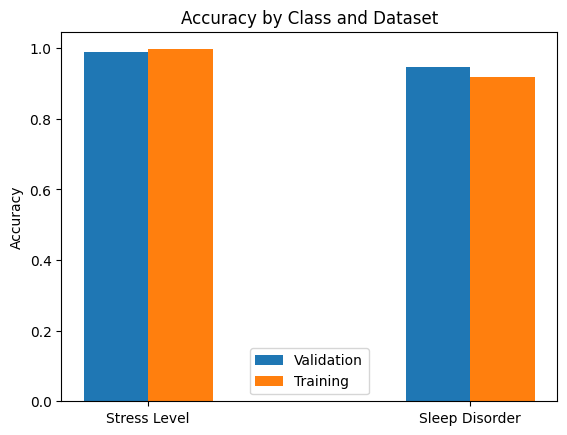

In [ ]:
import numpy as np


labels = ['Stress Level', 'Sleep Disorder']
validation_accuracies = [stress_level_accuracy_val, sleep_disorder_accuracy_val]
training_accuracies = [stress_level_accuracy_train, sleep_disorder_accuracy_train]

x = np.arange(len(labels))  # Create an array of evenly spaced values
width = 0.2

fig, ax = plt.subplots()
rects1 = ax.bar(x - width/2, validation_accuracies, width, label='Validation')
rects2 = ax.bar(x + width/2, training_accuracies, width, label='Training')

ax.set_ylabel('Accuracy')
ax.set_title('Accuracy by Class and Dataset')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()

plt.show()

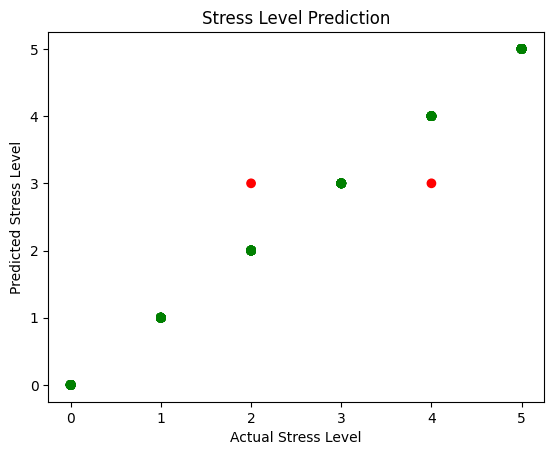

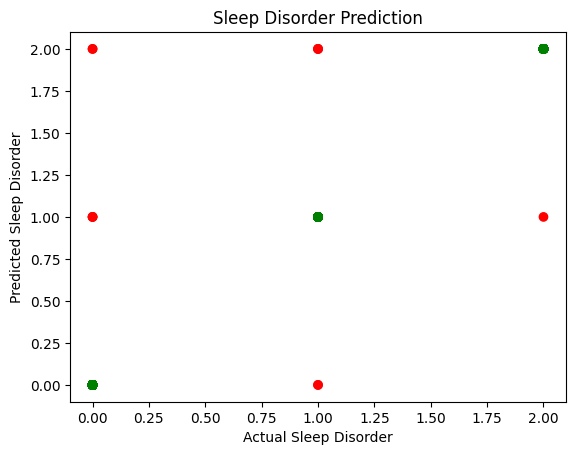

In [ ]:
import matplotlib.pyplot as plt
# Create a scatter plot for Stress Level with different colors for each data point
colors = ['green' if actual == predicted else 'red' for actual, predicted in zip(y_val['Stress Level'], multi_output_svm.predict(X_val)[:, 0])]
plt.scatter(y_val['Stress Level'], multi_output_svm.predict(X_val)[:, 0], c=colors)
plt.xlabel("Actual Stress Level")
plt.ylabel("Predicted Stress Level")
plt.title("Stress Level Prediction")
plt.show()

# Create a scatter plot for Sleep Disorder with different colors for each data point
colors = ['green' if actual == predicted else 'red' for actual, predicted in zip(y_val['Sleep Disorder'], multi_output_svm.predict(X_val)[:, 1])]
plt.scatter(y_val['Sleep Disorder'], multi_output_svm.predict(X_val)[:, 1], c=colors)
plt.xlabel("Actual Sleep Disorder")
plt.ylabel("Predicted Sleep Disorder")
plt.title("Sleep Disorder Prediction")
plt.show()


In [ ]:
# Calculate the confusion matrix for each target variable
from sklearn.metrics import confusion_matrix
import pylab as pl

stress_confusion_matrix = confusion_matrix(y_val['Stress Level'], y_pred[:, 0])
sleep_disorder_confusion_matrix = confusion_matrix(y_val['Sleep Disorder'], y_pred[:, 1])

# Print the confusion matrices
print("Stress Level Confusion Matrix:\n", stress_confusion_matrix)
print("\nSleep Disorder Confusion Matrix:\n", sleep_disorder_confusion_matrix)




Stress Level Confusion Matrix:
 [[38  0  0  0  0  0]
 [ 0 45  0  0  0  0]
 [ 0  0 26  1  0  0]
 [ 0  0  0 27  0  0]
 [ 0  0  0  1 20  0]
 [ 0  0  0  0  0 48]]

Sleep Disorder Confusion Matrix:
 [[124   3   2]
 [  2  27   3]
 [  0   1  44]]


PREDICTION OF TEST DATASET

In [ ]:
# Predict the stress level and sleep disorder on the test data
y_pred_test = multi_output_svm.predict(X_test)

# Print the third row of the test data
print("Third row of the test data:")
print(X_test[2])

# Print the actual y test values for the third row
print("\nActual y test values for the third row:")
print(y_test.iloc[2])

# Print the predicted values for the third row
print("\nPredicted values for the third row:")
print(y_pred_test[2])


Third row of the test data:
[-1.0073108   1.69343472  0.42946752  1.25679698  1.36657247  0.77077697
  1.06839609 -0.55669544  0.31794357  1.54332714  1.75336421]

Actual y test values for the third row:
Stress Level      0
Sleep Disorder    2
Name: 348, dtype: int64

Predicted values for the third row:
[0 2]


FUNCTION FOR PREDICTING INPUT DATA

In [ ]:
import numpy as np
def predict_stress_and_sleep_disorder(input_data):
  """
  This function takes in a list of input values and predicts the stress level and sleep disorder.

  Args:
    input_data: A list containing the following values:
      - Gender
      - Age
      - Occupation
      - Sleep Duration
      - Quality of Sleep
      - Physical Activity Level
      - BMI Category
      - Heart Rate
      - Daily Steps
      - SystolicBP
      - DiastolicBP

  Returns:
    A list containing the predicted stress level and sleep disorder.
  """

  # Convert the input values to their corresponding numerical values
    # Predict the stress level and sleep disorder
  rows = len(input_data)
  for i in range(0, rows+1):
    gender_map = {'Female': 0, 'Male': 1}
    occupation_map = {'Accountant': 1, 'Doctor': 2, 'Engineer': 3, 'Lawyer': 4, 'Manager': 5, 'Nurse':6,  'Salesperson': 7, 'Sales Representative': 8,
                                         'Scientist': 9,'Software Engineer':10, 'Teacher': 11}
    bmi_map = {'Underweight': 0, 'Normal Weight': 1, 'Normal': 1,  'Overweight': 2, 'Obese': 3}


    input_data[i][0] = gender_map[input_data[i][0]]
    input_data[i][2] = occupation_map[input_data[i][2]]
    input_data[i][6] = bmi_map[input_data[i][6]]

    # Convert the input data to a NumPy array
    input_data_as_numpy_array = np.asarray(input_data)

     # Standardize the input data
    std_data = scaler.transform(input_data_as_numpy_array.reshape(1, -1))

    prediction = multi_output_svm.predict(std_data)
    stress_level = 'Low' if prediction[i][0] < 5 else 'High'
    sleep_disorder = 'No Disorder' if prediction[i][1] == 0 else 'Insomnia' if prediction[i][1] == 1 else 'Sleep Apnea'
  # Return the predicted stress level and sleep disorder
    return stress_level, sleep_disorder


In [ ]:
def predict_stress_and_sleep_disorder(input_data):
    """
    This function takes in a list of input values and predicts the stress level and sleep disorder.

    Args:
      input_data: A list of lists, each containing the following values:
        - Gender
        - Age
        - Occupation
        - Sleep Duration
        - Quality of Sleep
        - Physical Activity Level
        - BMI Category
        - Heart Rate
        - Daily Steps
        - SystolicBP
        - DiastolicBP

    Returns:
      A list of tuples containing the predicted stress level and sleep disorder for each input.
    """

    gender_map = {'Female': 0, 'Male': 1}
    occupation_map = {
        'Accountant': 1, 'Doctor': 2, 'Engineer': 3, 'Lawyer': 4, 'Manager': 5,
        'Nurse': 6, 'Salesperson': 7, 'Sales Representative': 8, 'Scientist': 9,
        'Software Engineer': 10, 'Teacher': 11
    }
    bmi_map = {'Underweight': 0, 'Normal Weight': 1, 'Normal': 1, 'Overweight': 2, 'Obese': 3}

    for i in range(len(input_data)):
        input_data[i][0] = gender_map[input_data[i][0]]
        input_data[i][2] = occupation_map[input_data[i][2]]
        input_data[i][6] = bmi_map[input_data[i][6]]

    # Convert the input data to a NumPy array
    input_data_as_numpy_array = np.asarray(input_data)

    # Standardize the input data
    std_data = scaler.fit_transform(input_data_as_numpy_array)

    # Make predictions
    predictions = multi_output_svm.predict(std_data)

    results = []
    for prediction in predictions:
        stress_level = 'Low' if prediction[0] < 5 else 'High'
        sleep_disorder = 'No Disorder' if prediction[1] == 0 else 'Insomnia' if prediction[1] == 1 else 'Sleep Apnea'
        results.append((stress_level, sleep_disorder))

    return results

In [ ]:
# Example usage for prediction
input_data = [['Male', 1, 'Sales Representative', 5.9, 0, 0, 'Obese', 17, 0, 140, 90],
              ['Female', 1, 'Sales Representative', 5.9, 0, 0, 'Obese', 17, 0, 140, 90]]

predicted_stress_level, predicted_sleep_disorder = predict_stress_and_sleep_disorder(input_data)

print("Predicted Stress Level:", predicted_stress_level)
print("Predicted Sleep Disorder:", predicted_sleep_disorder)


Predicted Stress Level: ('Low', 'No Disorder')
Predicted Sleep Disorder: ('Low', 'No Disorder')
